## 06 Thống kê suy luận và A/B testing

Notebook này kiểm tra xem các khác biệt đã thấy ở phần EDA có phải do ngẫu nhiên không. Nội dung gồm thống kê mô tả, xác suất, khoảng tin cậy, kiểm định giả thuyết cho cả 5 câu hỏi nghiên cứu và một phân tích kiểu A/B.

Đầu vào là `data/processed/games_features.csv` (đã bỏ nhóm owners = "0 - 0" và năm 2026).

### 6.1. Thống kê mô tả

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

sns.set_theme(style="whitegrid", palette="Set2")

data = pd.read_csv("../data/processed/games_features.csv", low_memory=False)
print("Số game:", len(data))

cac_cot = ["Price", "Peak CCU", "Total reviews", "Positive ratio", "Median playtime forever"]
mo_ta = pd.DataFrame({
    "Số game": data[cac_cot].count(),
    "Trung bình": data[cac_cot].mean(),
    "Trung vị": data[cac_cot].median(),
    "Độ lệch chuẩn": data[cac_cot].std(),
    "Độ lệch (skew)": data[cac_cot].skew(),
})
display(mo_ta.round(2))

Số game: 100025


,Số game,Trung bình,Trung vị,Độ lệch chuẩn,Độ lệch (skew)
Price,100025,5.21,2.99,11.59,28.32
Peak CCU,100025,66.59,0.00,4128.81,189.66
Total reviews,100025,1484.08,14.00,36126.17,159.47
Positive ratio,56166,77.25,81.27,17.88,-1.05
Median playtime forever,100025,204.47,0.00,12375.31,239.99


Nhận xét: trung bình và trung vị chênh nhau rất xa ở Peak CCU, Total reviews và thời gian chơi, độ lệch đều trên 100. Vì vậy các phần sau dùng trung vị, tỷ lệ và kiểm định phi tham số.

### 6.2. Xác suất

Ở đây xác suất được ước lượng bằng tần suất trong dữ liệu. Sự kiện A là game có người chơi đồng thời (Peak CCU > 0), sự kiện B là game có Steam Cloud.

Peak CCU là số người chơi cùng lúc cao nhất trong một ngày, không phải đỉnh trong lịch sử của game (xem `docs/data_dictionary.md`). Vì vậy "game có người chơi đồng thời" ở đây nghĩa là Peak CCU > 0, tức game còn người chơi vào ngày dữ liệu được ghi nhận. Peak CCU = 0 không có nghĩa game chưa từng có người chơi.

In [2]:
A = data["has_ccu"] == 1
B = data["cat_Steam Cloud"] == 1

p_a = A.mean()
p_b = B.mean()
p_a_va_b = (A & B).mean()
p_a_khi_b = A[B].mean()
p_a_khi_khong_b = A[~B].mean()

print("P(A) =", round(p_a, 3))
print("P(B) =", round(p_b, 3))
print("P(A và B) =", round(p_a_va_b, 3))
print("P(A) x P(B) =", round(p_a * p_b, 3))
print("P(A | B) =", round(p_a_khi_b, 3))
print("P(A | không B) =", round(p_a_khi_khong_b, 3))

# Định lý Bayes: tính P(B | A) từ P(A | B), rồi so với cách đếm trực tiếp
p_b_khi_a = p_a_khi_b * p_b / p_a
print("P(B | A) theo Bayes =", round(p_b_khi_a, 3))
print("P(B | A) đếm trực tiếp =", round(B[A].mean(), 3))

P(A) = 0.194
P(B) = 0.28
P(A và B) = 0.099
P(A) x P(B) = 0.054
P(A | B) = 0.354
P(A | không B) = 0.132
P(B | A) theo Bayes = 0.51
P(B | A) đếm trực tiếp = 0.51


Nhận xét:

- Nếu A và B độc lập thì P(A và B) phải bằng P(A) x P(B). Ở đây 0,099 lớn hơn nhiều so với 0,054, nên hai sự kiện không độc lập.
- Game có Steam Cloud có xác suất có Peak CCU > 0 là 35,4%, so với 13,2% ở game không có.
- Định lý Bayes cho P(B | A) = 0,51, đúng bằng kết quả đếm trực tiếp: một nửa số game có Peak CCU > 0 có Steam Cloud, trong khi chỉ 28% tổng số game có tính năng này.

### 6.3. Định lý giới hạn trung tâm

Giá game lệch rất mạnh, nhưng trung bình của các mẫu ngẫu nhiên sẽ gần phân phối chuẩn khi cỡ mẫu đủ lớn. Đây là cơ sở của khoảng tin cậy ở mục sau.

n = 5 - độ lệch của phân phối trung bình mẫu: 17.6
n = 30 - độ lệch của phân phối trung bình mẫu: 4.91


n = 500 - độ lệch của phân phối trung bình mẫu: 1.34


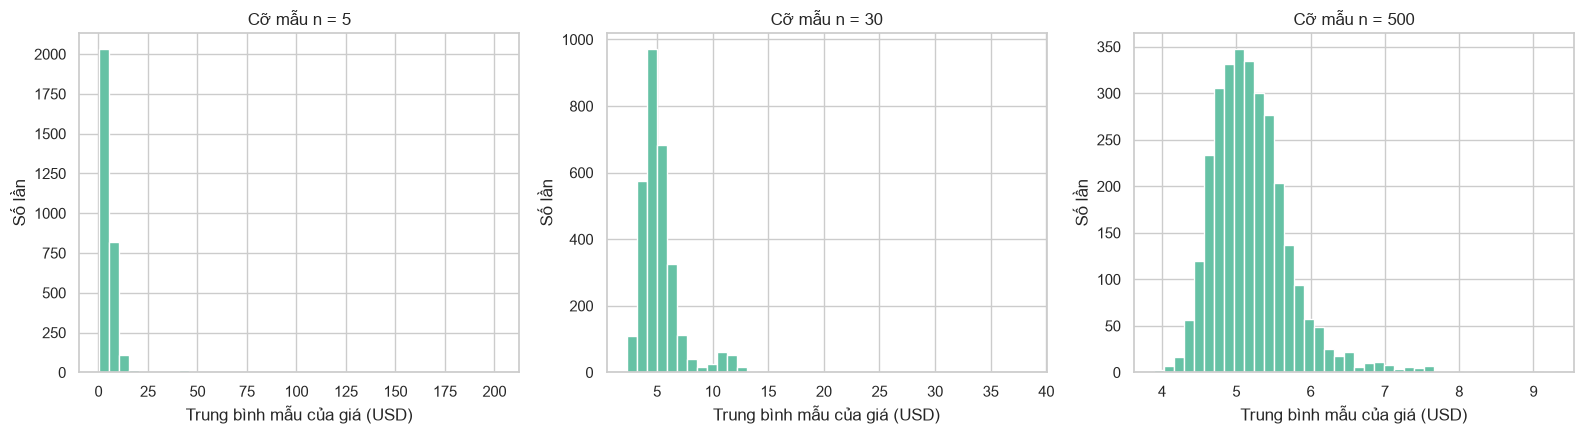

In [3]:
rng = np.random.default_rng(42)
gia = data["Price"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
i = 0
for co_mau in [5, 30, 500]:
    cac_trung_binh = []
    for lan in range(3000):
        mau = rng.choice(gia, size=co_mau)
        cac_trung_binh.append(mau.mean())
    axes[i].hist(cac_trung_binh, bins=40)
    axes[i].set(title="Cỡ mẫu n = " + str(co_mau), xlabel="Trung bình mẫu của giá (USD)", ylabel="Số lần")
    print("n =", co_mau, "- độ lệch của phân phối trung bình mẫu:", round(pd.Series(cac_trung_binh).skew(), 2))
    i = i + 1
plt.tight_layout()
plt.show()

Nhận xét: phân phối trung bình mẫu gần chuẩn dần khi n tăng, độ lệch giảm từ 17,6 (n = 5) xuống 1,34 (n = 500). Giá có vài giá trị cực lớn nên cần cỡ mẫu khá lớn. Dự án có hàng chục nghìn game nên dùng được xấp xỉ chuẩn.

### 6.4. Khoảng tin cậy 95%

Với tỷ lệ dùng công thức p ± 1,96 × căn(p(1-p)/n). Với trung vị không có công thức đơn giản nên dùng bootstrap: lấy mẫu lại có hoàn lại nhiều lần, tính trung vị mỗi lần, rồi lấy phân vị 2,5% và 97,5%.

In [4]:
# Khoảng tin cậy cho tỷ lệ game có người chơi đồng thời
n = len(data)
p = data["has_ccu"].mean()
sai_so = 1.96 * np.sqrt(p * (1 - p) / n)
print("Tỷ lệ has_ccu:", round(p * 100, 2), "%, khoảng tin cậy:",
      round((p - sai_so) * 100, 2), "đến", round((p + sai_so) * 100, 2), "%")

# Bootstrap cho chênh lệch trung vị Positive ratio giữa game có và không có Achievements
danh_gia = data[data["Positive ratio"].notna()]
nhom_co = danh_gia[danh_gia["has_achievements"] == 1]["Positive ratio"].to_numpy()
nhom_khong = danh_gia[danh_gia["has_achievements"] == 0]["Positive ratio"].to_numpy()

cac_chenh_lech = []
for lan in range(1000):
    mau_co = rng.choice(nhom_co, size=len(nhom_co))
    mau_khong = rng.choice(nhom_khong, size=len(nhom_khong))
    cac_chenh_lech.append(np.median(mau_co) - np.median(mau_khong))

print("Chênh lệch trung vị:", round(np.median(nhom_co) - np.median(nhom_khong), 2), "điểm %")
print("Khoảng tin cậy bootstrap:", round(np.percentile(cac_chenh_lech, 2.5), 2), "đến",
      round(np.percentile(cac_chenh_lech, 97.5), 2))

Tỷ lệ has_ccu: 19.4 %, khoảng tin cậy: 19.15 đến 19.64 %


Chênh lệch trung vị: 6.75 điểm %
Khoảng tin cậy bootstrap: 6.41 đến 7.14


Nhận xét:

- Tỷ lệ game có người chơi đồng thời là 19,4%, khoảng tin cậy rất hẹp (19,15% đến 19,64%) vì dữ liệu lớn.
- Game có Achievements có trung vị Positive ratio cao hơn 6,75 điểm, khoảng tin cậy 6,41 đến 7,14. Khoảng này không chứa 0 nên chênh lệch khó là do ngẫu nhiên.

### 6.5. Kiểm định giả thuyết cho các câu hỏi nghiên cứu

Giả thuyết H0 của mỗi kiểm định là không có liên hệ hoặc không có khác biệt. Mức ý nghĩa là 0,05. Vì dữ liệu lệch mạnh, không theo phân phối chuẩn, nên dùng các kiểm định phi tham số:

- Mann-Whitney U để so sánh hai nhóm.
- Kruskal-Wallis để so sánh nhiều nhóm.
- Chi bình phương cho hai biến phân loại.
- Spearman cho hai biến số.

Dữ liệu rất lớn nên khác biệt nhỏ cũng có p rất bé. Vì vậy bảng kết quả có thêm cỡ ảnh hưởng (effect size) để biết khác biệt lớn hay nhỏ. Có nhiều kiểm định cùng lúc nên dùng hiệu chỉnh Bonferroni.

Với game miễn phí, chỉ xét game phát hành đến năm 2020, vì từ 2021 phần lớn game miễn phí bị thiếu dữ liệu owners (notebook 03) nên nhóm còn lại không đại diện.

In [5]:
# 4 hàm nhỏ, mỗi hàm chạy một loại kiểm định và trả về: tên kiểm định, số game, p, cỡ ảnh hưởng

def kiem_dinh_hai_nhom(nhom_1, nhom_2):
    u, p = stats.mannwhitneyu(nhom_1, nhom_2)
    # rank-biserial: từ -1 đến 1, càng xa 0 thì khác biệt càng lớn
    r = 2 * u / (len(nhom_1) * len(nhom_2)) - 1
    return "Mann-Whitney U", len(nhom_1) + len(nhom_2), p, "r = " + str(round(r, 3))


def kiem_dinh_nhieu_nhom(du_lieu, cot_nhom, cot_gia_tri):
    cac_nhom = []
    for ten, nhom in du_lieu.groupby(cot_nhom):
        cac_nhom.append(nhom[cot_gia_tri].to_numpy())
    h, p = stats.kruskal(*cac_nhom)
    n = len(du_lieu)
    eta2 = (h - len(cac_nhom) + 1) / (n - len(cac_nhom))
    return "Kruskal-Wallis", n, p, "eta2 = " + str(round(eta2, 3))


def kiem_dinh_chi2(du_lieu, cot_1, cot_2):
    bang = pd.crosstab(du_lieu[cot_1], du_lieu[cot_2])
    chi2, p, bac_tu_do, ky_vong = stats.chi2_contingency(bang)
    n = bang.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(bang.shape) - 1)))
    return "Chi bình phương", n, p, "V = " + str(round(v, 3))


def kiem_dinh_spearman(du_lieu, cot_1, cot_2):
    cap = du_lieu[[cot_1, cot_2]].dropna()
    rho, p = stats.spearmanr(cap[cot_1], cap[cot_2])
    return "Spearman", len(cap), p, "rho = " + str(round(rho, 3))


danh_gia = data[data["Positive ratio"].notna()]
gio_choi = data[data["Median playtime forever"] > 0]
den_2020 = data[data["Năm phát hành"] <= 2020]
danh_gia_den_2020 = den_2020[den_2020["Positive ratio"].notna()]

ds_kiem_dinh = [
    ("RQ1", "Owners và Peak CCU", kiem_dinh_spearman(data, "Owners_mid", "Peak CCU")),
    ("RQ1", "MMO và có người chơi đồng thời", kiem_dinh_chi2(data, "genre_Massively Multiplayer", "has_ccu")),
    ("RQ2", "Metacritic và tỷ lệ tích cực", kiem_dinh_spearman(danh_gia, "Metacritic score", "Positive ratio")),
    ("RQ2", "Tỷ lệ tích cực: MMO và game khác", kiem_dinh_hai_nhom(
        danh_gia[danh_gia["genre_Massively Multiplayer"] == 1]["Positive ratio"],
        danh_gia[danh_gia["genre_Massively Multiplayer"] == 0]["Positive ratio"])),
    ("RQ3", "Thời gian chơi theo nhóm giá", kiem_dinh_nhieu_nhom(gio_choi, "Nhóm giá", "Median playtime forever")),
    ("RQ3", "Thời gian chơi: RPG và game khác", kiem_dinh_hai_nhom(
        gio_choi[gio_choi["genre_RPG"] == 1]["Median playtime forever"],
        gio_choi[gio_choi["genre_RPG"] == 0]["Median playtime forever"])),
    ("RQ4", "Tỷ lệ tích cực theo giai đoạn", kiem_dinh_nhieu_nhom(danh_gia, "Giai đoạn", "Positive ratio")),
    ("RQ4", "Giai đoạn và có người chơi đồng thời", kiem_dinh_chi2(data, "Giai đoạn", "has_ccu")),
    ("RQ5", "Nhóm giá và có người chơi (đến 2020)", kiem_dinh_chi2(den_2020, "Nhóm giá", "has_ccu")),
    ("RQ5", "Peak CCU: miễn phí và trả phí (đến 2020)", kiem_dinh_hai_nhom(
        den_2020[den_2020["is_free"] == 1]["Peak CCU"],
        den_2020[den_2020["is_free"] == 0]["Peak CCU"])),
    ("RQ5", "Giá và tỷ lệ tích cực", kiem_dinh_spearman(danh_gia, "Price", "Positive ratio")),
]

nguong_bonferroni = 0.05 / len(ds_kiem_dinh)
print("Ngưỡng sau hiệu chỉnh Bonferroni:", round(nguong_bonferroni, 5))

dong = []
for rq, noi_dung, (ten, so_game, p, cho_anh_huong) in ds_kiem_dinh:
    if p < 0.001:
        p_hien_thi = "< 0,001"
    else:
        p_hien_thi = str(round(p, 3))
    dong.append({"RQ": rq, "Nội dung": noi_dung, "Kiểm định": ten, "Số game": so_game,
                 "p": p_hien_thi, "Cỡ ảnh hưởng": cho_anh_huong,
                 "Bác bỏ H0": p < nguong_bonferroni})

bang_kiem_dinh = pd.DataFrame(dong)
pd.set_option("display.max_colwidth", 60)
display(bang_kiem_dinh)

Ngưỡng sau hiệu chỉnh Bonferroni: 0.00455


,RQ,Nội dung,Kiểm định,Số game,p,Cỡ ảnh hưởng,Bác bỏ H0
0,RQ1,Owners và Peak CCU,Spearman,100025,"< 0,001",rho = 0.469,True
1,RQ1,MMO và có người chơi đồng thời,Chi bình phương,100025,"< 0,001",V = 0.05,True
2,RQ2,Metacritic và tỷ lệ tích cực,Spearman,4137,"< 0,001",rho = 0.583,True
3,RQ2,Tỷ lệ tích cực: MMO và game khác,Mann-Whitney U,56166,"< 0,001",r = -0.42,True
4,RQ3,Thời gian chơi theo nhóm giá,Kruskal-Wallis,25912,"< 0,001",eta2 = 0.08,True
5,RQ3,Thời gian chơi: RPG và game khác,Mann-Whitney U,25912,"< 0,001",r = 0.206,True
6,RQ4,Tỷ lệ tích cực theo giai đoạn,Kruskal-Wallis,56166,"< 0,001",eta2 = 0.072,True
7,RQ4,Giai đoạn và có người chơi đồng thời,Chi bình phương,100025,"< 0,001",V = 0.175,True
8,RQ5,Nhóm giá và có người chơi (đến 2020),Chi bình phương,38886,"< 0,001",V = 0.095,True
9,RQ5,Peak CCU: miễn phí và trả phí (đến 2020),Mann-Whitney U,38886,"< 0,001",r = 0.035,True


Nhận xét:

- Cả 11 kiểm định đều bác bỏ H0 kể cả sau hiệu chỉnh Bonferroni. Điều này không bất ngờ vì cỡ mẫu rất lớn, nên cần xem cỡ ảnh hưởng.
- Liên hệ rõ: Metacritic và tỷ lệ tích cực (rho 0,583), owners và Peak CCU (rho 0,469), MMO có tỷ lệ tích cực thấp hơn game khác (r = -0,42).
- Liên hệ vừa hoặc yếu: thời gian chơi của RPG (r = 0,206), giai đoạn và has_ccu (V = 0,175), giá và thời gian chơi (eta2 = 0,08), giai đoạn và tỷ lệ tích cực (eta2 = 0,072).
- Rất yếu: giá và tỷ lệ tích cực (rho 0,12), nhóm giá và has_ccu (V = 0,095), MMO và has_ccu (V = 0,05).
- Peak CCU của game miễn phí và trả phí gần như không khác nhau (r = 0,035), dù p rất nhỏ. Đây là ví dụ cho thấy có ý nghĩa thống kê không có nghĩa là khác biệt lớn.

### 6.6. Kiểm tra lại RQ5 sau khi bỏ nhóm thiếu dữ liệu

Báo cáo giữa kỳ kết luận tỷ lệ game có người chơi đồng thời tăng đều theo nhóm giá, từ 8,2% ở nhóm miễn phí. Con số 8,2% tính cả nhóm owners = "0 - 0". Phần này tính lại trên dữ liệu đã bỏ nhóm đó, chỉ xét game đến 2020. Số ở đây có thể lệch một chút so với notebook 02 vì notebook 03 bỏ thêm các game thiếu Genres, Categories.

,so_game,pct_co_ccu,ccu_trung_binh,ccu_trung_vi,pct_tu_20k,tich_cuc_trung_vi
Nhóm giá,,,,,,
Miễn phí,5686,25.4,463.6,0.0,50.9,77.1
Thấp,24276,19.9,27.3,0.0,37.1,76.5
Trung bình,7572,26.5,86.3,0.0,33.9,80.0
Cao,1352,36.7,283.7,0.0,36.9,75.8


Game miễn phí có người chơi đồng thời: 25.4 %
Game trả phí có người chơi đồng thời: 22.1 %
                      Name  Peak CCU
27        Counter-Strike 2   1013936
23                  Dota 2    623941
12776  PUBG: BATTLEGROUNDS    314682
3 game lớn nhất chiếm: 74.1 %
Peak CCU trung bình khi bỏ 10 game lớn nhất: 48.4
Peak CCU trung bình của game trả phí: 51.2


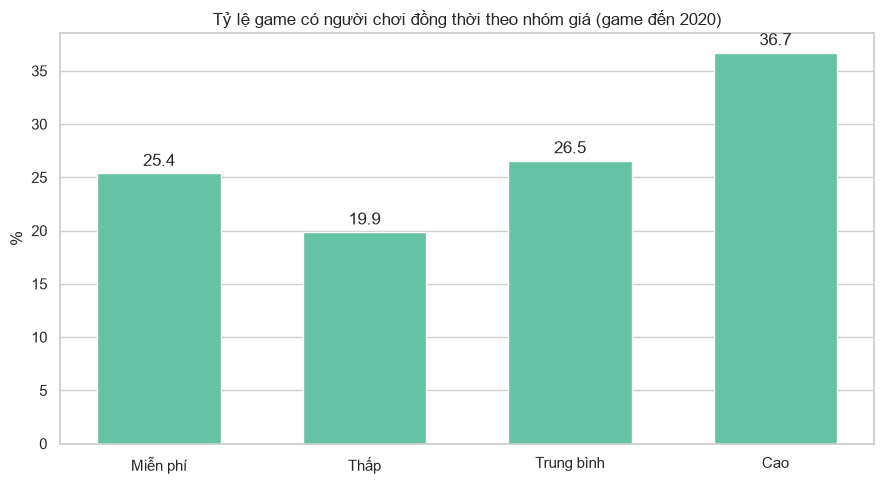

In [6]:
thu_tu_gia = ["Miễn phí", "Thấp", "Trung bình", "Cao"]

bang_gia = den_2020.groupby("Nhóm giá").agg(
    so_game=("id", "size"),
    pct_co_ccu=("has_ccu", lambda s: s.mean() * 100),
    ccu_trung_binh=("Peak CCU", "mean"),
    ccu_trung_vi=("Peak CCU", "median"),
    pct_tu_20k=("Owners_mid", lambda s: (s >= 35000).mean() * 100),
).reindex(thu_tu_gia)
tich_cuc = danh_gia_den_2020.groupby("Nhóm giá")["Positive ratio"].median().reindex(thu_tu_gia)
bang_gia["tich_cuc_trung_vi"] = tich_cuc
display(bang_gia.round(1))

print("Game miễn phí có người chơi đồng thời:", round(den_2020[den_2020["is_free"] == 1]["has_ccu"].mean() * 100, 1), "%")
print("Game trả phí có người chơi đồng thời:", round(den_2020[den_2020["is_free"] == 0]["has_ccu"].mean() * 100, 1), "%")

# Ba game miễn phí lớn nhất chiếm bao nhiêu tổng Peak CCU của nhóm miễn phí
ccu_mien_phi = den_2020[den_2020["is_free"] == 1].sort_values("Peak CCU", ascending=False)
print(ccu_mien_phi[["Name", "Peak CCU"]].head(3))
print("3 game lớn nhất chiếm:", round(ccu_mien_phi["Peak CCU"].head(3).sum() / ccu_mien_phi["Peak CCU"].sum() * 100, 1), "%")
print("Peak CCU trung bình khi bỏ 10 game lớn nhất:", round(ccu_mien_phi["Peak CCU"].iloc[10:].mean(), 1))
print("Peak CCU trung bình của game trả phí:", round(den_2020[den_2020["is_free"] == 0]["Peak CCU"].mean(), 1))

plt.figure(figsize=(9, 5))
ax = plt.gca()
ax.bar(bang_gia.index, bang_gia["pct_co_ccu"], width=0.6)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set(title="Tỷ lệ game có người chơi đồng thời theo nhóm giá (game đến 2020)", ylabel="%")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Nhận xét:

- Kết quả khác với báo cáo giữa kỳ. Báo cáo ghi tỷ lệ tăng đều từ 8,2% (miễn phí) đến 33,3% (cao). Sau khi bỏ nhóm thiếu dữ liệu, nhóm miễn phí là 25,4%, cao hơn nhóm thấp (19,9%) và gần bằng nhóm trung bình (26,5%).
- Giữa các nhóm trả phí, giá cao hơn vẫn đi kèm tỷ lệ cao hơn (19,9%, 26,5%, 36,7%). Phần này của kết luận vẫn đúng.
- Tỷ lệ game từ 20.000 người sở hữu thì không tăng theo giá: game miễn phí 50,9%, ba nhóm trả phí 37,1%, 33,9% và 36,9%.
- Game miễn phí có 25,4% có người chơi đồng thời, game trả phí 22,1%, tức gần bằng nhau chứ không thấp hơn một nửa như báo cáo giữa kỳ (8,2% và 17,6%).
- Peak CCU trung bình của game miễn phí (463,6) cao hơn nhiều, nhưng trung vị cả hai nhóm đều bằng 0, và Counter-Strike 2, Dota 2, PUBG chiếm 74,1% tổng Peak CCU của nhóm miễn phí. Bỏ 10 game lớn nhất thì trung bình còn 48,4, gần bằng game trả phí (51,2). Kết luận rằng vài game rất lớn kéo trung bình lên vẫn đúng.
- Nhóm giá trung bình vẫn có tỷ lệ tích cực cao nhất (80,0%).

Trả lời lại RQ5: trong các game trả phí, giá cao hơn đi kèm tỷ lệ có người chơi đồng thời cao hơn, nhưng không đi kèm tỷ lệ có nhiều người sở hữu cao hơn. Game miễn phí không thua game trả phí về độ phổ biến. Giá liên hệ rất yếu với đánh giá.

### 6.7. Phân tích kiểu A/B: Achievements và đánh giá tốt

A/B testing thật cần chia ngẫu nhiên người dùng hoặc sản phẩm vào hai nhóm. Dữ liệu này là dữ liệu quan sát nên không làm được đúng nghĩa. Phần này vẫn làm theo các bước của A/B test để so sánh hai nhóm, nhưng kết quả chỉ là mối liên hệ.

- Nhóm A: game không có Achievements.
- Nhóm B: game có Achievements.
- Chỉ số: tỷ lệ game được đánh giá tốt, tức Positive ratio từ 80% trở lên.
- H0: tỷ lệ của hai nhóm bằng nhau.

In [7]:
danh_gia = data[data["Positive ratio"].notna()].copy()
danh_gia["danh_gia_tot"] = (danh_gia["Positive ratio"] >= 80).astype(int)

nhom_a = danh_gia[danh_gia["has_achievements"] == 0]["danh_gia_tot"]
nhom_b = danh_gia[danh_gia["has_achievements"] == 1]["danh_gia_tot"]

so_tot = [nhom_b.sum(), nhom_a.sum()]
so_game = [len(nhom_b), len(nhom_a)]
z, p = proportions_ztest(so_tot, so_game)

ty_le_a = nhom_a.mean()
ty_le_b = nhom_b.mean()
chenh_lech = ty_le_b - ty_le_a
sai_so = 1.96 * np.sqrt(ty_le_a * (1 - ty_le_a) / len(nhom_a) + ty_le_b * (1 - ty_le_b) / len(nhom_b))

print("Nhóm A:", len(nhom_a), "game, tỷ lệ tốt", round(ty_le_a * 100, 1), "%")
print("Nhóm B:", len(nhom_b), "game, tỷ lệ tốt", round(ty_le_b * 100, 1), "%")
print("Chênh lệch:", round(chenh_lech * 100, 1), "điểm %, khoảng tin cậy:",
      round((chenh_lech - sai_so) * 100, 1), "đến", round((chenh_lech + sai_so) * 100, 1))
print("z =", round(z, 2), ", p =", p)

Nhóm A: 19633 game, tỷ lệ tốt 44.2 %
Nhóm B: 36533 game, tỷ lệ tốt 58.6 %
Chênh lệch: 14.5 điểm %, khoảng tin cậy: 13.6 đến 15.3
z = 32.83 , p = 1.9944348734823033e-236


Hai nhóm này không được chia ngẫu nhiên, nên có thể khác nhau ở những yếu tố khác như giá và thời điểm phát hành. Bước dưới đây so sánh lại trong từng giai đoạn và từng nhóm giá.

In [8]:
ket_qua = []
for cot in ["Giai đoạn", "Nhóm giá"]:
    for ten, nhom in danh_gia.groupby(cot):
        a = nhom[nhom["has_achievements"] == 0]["danh_gia_tot"]
        b = nhom[nhom["has_achievements"] == 1]["danh_gia_tot"]
        ket_qua.append({"Chia theo": cot, "Nhóm": ten, "Số game A": len(a), "Số game B": len(b),
                        "Tỷ lệ A (%)": round(a.mean() * 100, 1), "Tỷ lệ B (%)": round(b.mean() * 100, 1),
                        "Chênh lệch": round((b.mean() - a.mean()) * 100, 1)})
display(pd.DataFrame(ket_qua))

# Tỷ lệ game có Achievements theo giai đoạn và nhóm giá
print("Tỷ lệ game có Achievements theo giai đoạn (%):")
print((danh_gia.groupby("Giai đoạn")["has_achievements"].mean() * 100).round(1))

,Chia theo,Nhóm,Số game A,Số game B,Tỷ lệ A (%),Tỷ lệ B (%),Chênh lệch
0,Giai đoạn,2014-2017,4514,7668,29.7,44.4,14.7
1,Giai đoạn,2018-2020,5898,9599,41.5,52.6,11.1
2,Giai đoạn,2021-2023,5544,11076,49.6,64.5,14.9
3,Giai đoạn,2024-2025,2680,7317,61.1,72.9,11.8
4,Giai đoạn,Trước 2014,997,873,49.6,56.4,6.7
5,Nhóm giá,Cao,989,1827,47.3,54.1,6.8
6,Nhóm giá,Miễn phí,4082,3171,43.3,50.6,7.3
7,Nhóm giá,Thấp,10486,22025,41.7,58.1,16.4
8,Nhóm giá,Trung bình,4076,9510,50.6,63.5,13.0


Tỷ lệ game có Achievements theo giai đoạn (%):
Giai đoạn
2014-2017     62.9
2018-2020     61.9
2021-2023     66.6
2024-2025     73.2
Trước 2014    46.7
Name: has_achievements, dtype: float64


Nếu làm A/B test thật, ví dụ một nhà phát hành thử hai trang cửa hàng khác nhau, cần tính trước cỡ mẫu. Ví dụ dưới đây tính số người cần cho mỗi nhóm để phát hiện tỷ lệ chuyển đổi tăng từ 5% lên 6%, với mức ý nghĩa 0,05 và power 0,8. Các con số 5% và 6% chỉ là giả định để minh họa.

In [9]:
cho_anh_huong = proportion_effectsize(0.06, 0.05)
co_mau = NormalIndPower().solve_power(effect_size=cho_anh_huong, alpha=0.05, power=0.8)
print("Số người cần cho mỗi nhóm:", int(np.ceil(co_mau)))

Số người cần cho mỗi nhóm: 8143


Nhận xét:

- Game có Achievements có tỷ lệ được đánh giá tốt cao hơn 14,5 điểm (58,6% so với 44,2%), khoảng tin cậy 13,6 đến 15,3.
- Chênh lệch này vẫn còn khi so trong từng giai đoạn (6,7 đến 14,9 điểm) và từng nhóm giá (6,8 đến 16,4 điểm), nên không phải chỉ do giá hay thời điểm phát hành.
- Vẫn không thể nói thêm Achievements làm game được đánh giá tốt hơn. Nhà phát triển làm Achievements thường đầu tư cho game nhiều hơn, và chất lượng này không đo được trong dữ liệu.
- Ví dụ về cỡ mẫu cho thấy để phát hiện mức tăng từ 5% lên 6% cần 8.143 người mỗi nhóm. Hiệu ứng càng nhỏ thì cần càng nhiều mẫu.

#### Lưu bảng kết quả

In [10]:
# Lưu các bảng chính để dùng trong báo cáo
bang_kiem_dinh.to_csv("../reports/tables/kiem_dinh_gia_thuyet.csv", encoding="utf-8-sig")
bang_gia.to_csv("../reports/tables/rq5_theo_nhom_gia_den_2020.csv", encoding="utf-8-sig")
print("Đã lưu bảng vào reports/tables")

Đã lưu bảng vào reports/tables
